# Employee Attrition Analysis - Project Milestone 3
Statistical Machine Learning (CSET211)

Dataset: IBM HR Analytics Employee Attrition & Performance (1470 rows)

Goal: find which employee factors are linked to attrition and compare using different models




# Section 1: Data Preprocessing

## Q1. Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, classification_report

## Q2. Load the dataset

In [2]:
df = pd.read_csv("/content/WA_Fn-UseC_-HR-Employee-Attrition.csv")
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


## Q3. Rows, columns and data types

In [3]:
print(df.shape)
df.info()

(1470, 35)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel     

## Q4. Descriptive statistics

In [4]:
df.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


## Q5. Check missing values and duplicate records

In [5]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values: 0
Duplicate rows: 0


Both are 0, so no imputation or duplicate removal is needed here.
(If there were missing values we would fill them with mean/median/mode.)

## Q6. Check the target column (Attrition) - class balance

Attrition
No     0.838776
Yes    0.161224
Name: proportion, dtype: float64


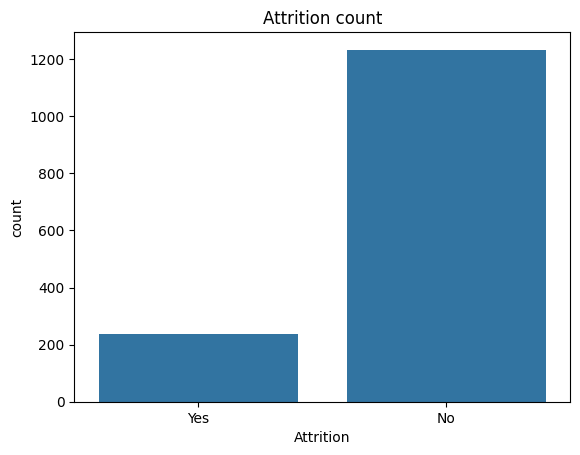

In [6]:
print(df["Attrition"].value_counts(normalize=True))
sns.countplot(x="Attrition", data=df)
plt.title("Attrition count")
plt.show()

Only about 16% of employees left, so the data is **imbalanced**. Accuracy alone can be misleading, so we also look at recall and F1.

## Q7. Drop columns that are useless (constant values and an ID column)

In [7]:
# columns with only 1 unique value
print(df.nunique()[df.nunique() == 1])

# drop constant columns and the ID column
df = df.drop(columns=["EmployeeCount", "StandardHours", "Over18", "EmployeeNumber"])
print(df.shape)

EmployeeCount    1
Over18           1
StandardHours    1
dtype: int64
(1470, 31)


## Q8. Convert the target to numbers (1 = left, 0 = stayed)

In [8]:
df["AttritionFlag"] = (df["Attrition"] == "Yes").astype(int)
print(df["AttritionFlag"].mean())

0.16122448979591836


## Q9. EDA: attrition rate within each group

In [9]:
for col in ["OverTime", "Department", "JobRole", "MaritalStatus", "BusinessTravel"]:
    print(df.groupby(col)["AttritionFlag"].mean().sort_values(ascending=False).round(3), "\n")

OverTime
Yes    0.305
No     0.104
Name: AttritionFlag, dtype: float64 

Department
Sales                     0.206
Human Resources           0.190
Research & Development    0.138
Name: AttritionFlag, dtype: float64 

JobRole
Sales Representative         0.398
Laboratory Technician        0.239
Human Resources              0.231
Sales Executive              0.175
Research Scientist           0.161
Manufacturing Director       0.069
Healthcare Representative    0.069
Manager                      0.049
Research Director            0.025
Name: AttritionFlag, dtype: float64 

MaritalStatus
Single      0.255
Married     0.125
Divorced    0.101
Name: AttritionFlag, dtype: float64 

BusinessTravel
Travel_Frequently    0.249
Travel_Rarely        0.150
Non-Travel           0.080
Name: AttritionFlag, dtype: float64 



## Q10. EDA: visualizations

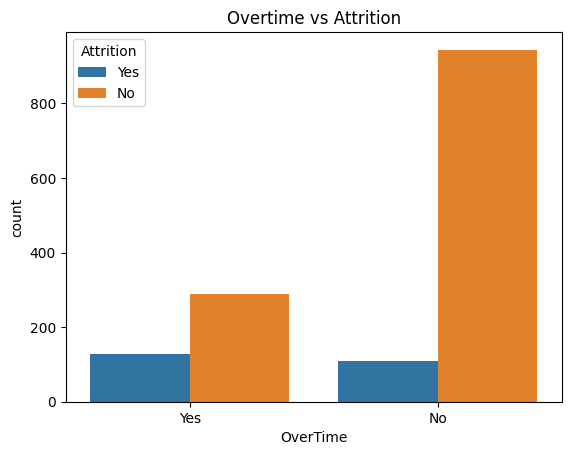

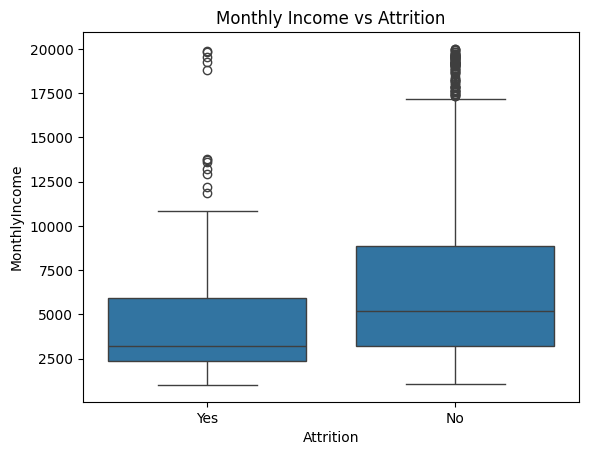

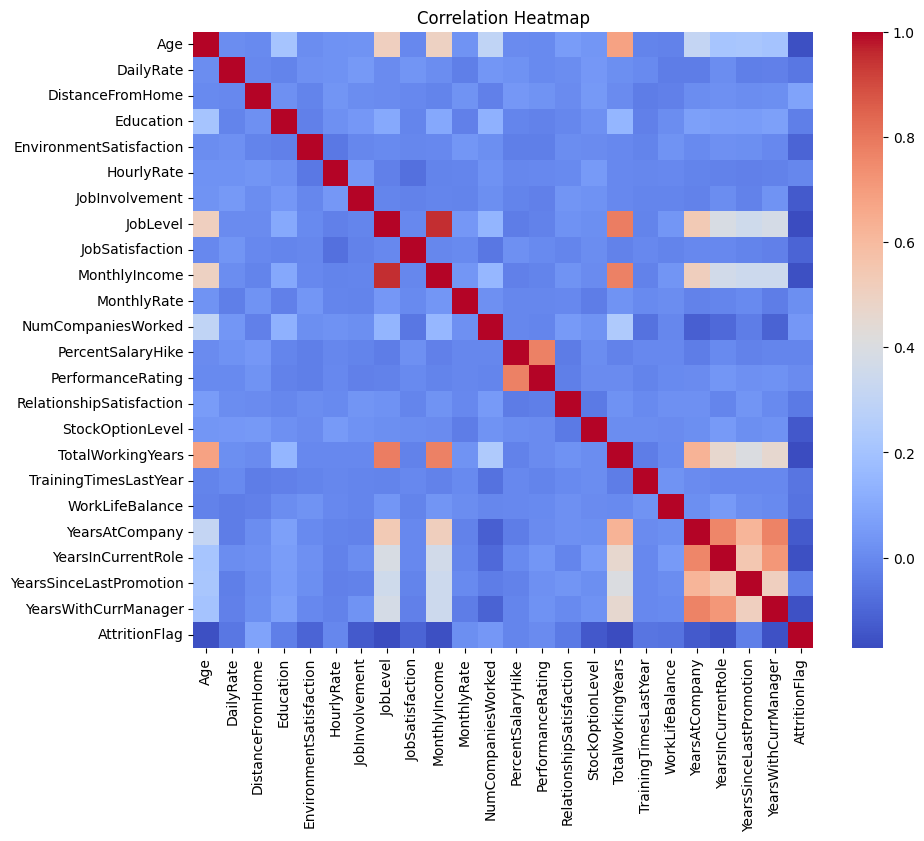

In [10]:
sns.countplot(x="OverTime", hue="Attrition", data=df)
plt.title("Overtime vs Attrition")
plt.show()

sns.boxplot(x="Attrition", y="MonthlyIncome", data=df)
plt.title("Monthly Income vs Attrition")
plt.show()

plt.figure(figsize=(10, 8))
sns.heatmap(df.select_dtypes("number").corr(), cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

## Q11. Separate features (X) and target (y)

In [11]:
X_raw = df.drop(columns=["Attrition", "AttritionFlag"])   # drop BOTH target columns from X
y = df["AttritionFlag"]

print("Text columns:", X_raw.select_dtypes(exclude="number").columns.tolist())
print("Before encoding:", X_raw.shape)
X_raw[["BusinessTravel", "OverTime"]].head()

Text columns: ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']
Before encoding: (1470, 30)


,BusinessTravel,OverTime
0,Travel_Rarely,Yes
1,Travel_Frequently,No
2,Travel_Rarely,Yes
3,Travel_Frequently,Yes
4,Travel_Rarely,No


## Q12. Encode categorical columns (one-hot encoding)

In [12]:
X = pd.get_dummies(X_raw, drop_first=True)   # drop_first avoids the dummy variable trap
print("After encoding:", X.shape)
X.filter(like="OverTime").head()

After encoding: (1470, 44)


,OverTime_Yes
0,True
1,False
2,True
3,True
4,False


## Q13. Split into training and testing data (80% / 20%)

In [13]:
# stratify=y keeps the same % of leavers in train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print(y_train.mean(), y_test.mean())

Training data: (1176, 44)
Testing data: (294, 44)
0.16156462585034015 0.1598639455782313


## Q14. Feature scaling (standardization)

In [14]:
cols = ["Age", "MonthlyIncome"]
print("Before scaling:")
print(X_train[cols].describe().loc[["mean", "std"]].round(2), "\n")

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # learn from training data only
X_test_scaled = scaler.transform(X_test)

print("After scaling:")
print(pd.DataFrame(X_train_scaled, columns=X_train.columns)[cols].describe().loc[["mean", "std"]].round(2))

Before scaling:
        Age  MonthlyIncome
mean  37.00        6544.02
std    9.18        4653.74 

After scaling:
      Age  MonthlyIncome
mean -0.0           -0.0
std   1.0            1.0


# Section 2: Models

## Q15. Train Logistic Regression and KNN (K=7)

In [15]:
# class_weight="balanced" makes mistakes on the rare 'left' class count more
log_model = LogisticRegression(class_weight="balanced", max_iter=1000)
log_model.fit(X_train_scaled, y_train)

knn_model = KNeighborsClassifier(n_neighbors=7)
knn_model.fit(X_train_scaled, y_train)

print("Both models trained.")

Both models trained.


## Q16. Evaluate: confusion matrix, accuracy, F1 and classification report

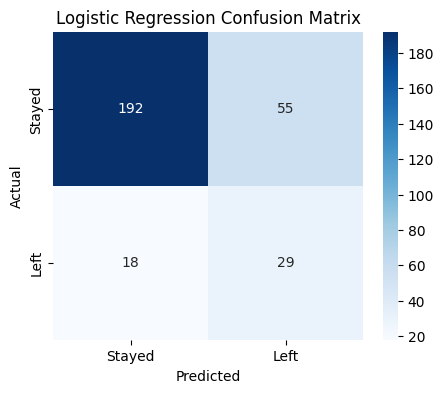

Logistic Regression
Accuracy: 0.752
F1 Score: 0.443
              precision    recall  f1-score   support

      Stayed       0.91      0.78      0.84       247
        Left       0.35      0.62      0.44        47

    accuracy                           0.75       294
   macro avg       0.63      0.70      0.64       294
weighted avg       0.82      0.75      0.78       294



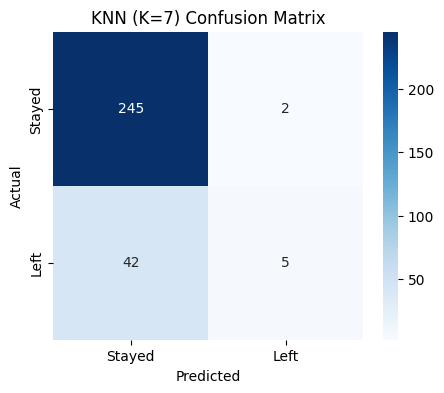

KNN (K=7)
Accuracy: 0.85
F1 Score: 0.185
              precision    recall  f1-score   support

      Stayed       0.85      0.99      0.92       247
        Left       0.71      0.11      0.19        47

    accuracy                           0.85       294
   macro avg       0.78      0.55      0.55       294
weighted avg       0.83      0.85      0.80       294



In [16]:
models = {"Logistic Regression": log_model, "KNN (K=7)": knn_model}
results = []

for name, model in models.items():
    y_pred = model.predict(X_test_scaled)
    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["Stayed", "Left"], yticklabels=["Stayed", "Left"])
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(name + " Confusion Matrix")
    plt.show()

    print(name)
    print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
    print("F1 Score:", round(f1_score(y_test, y_pred), 3))
    print(classification_report(y_test, y_pred, target_names=["Stayed", "Left"]))

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
    })

## Q17. Compare the two models

In [17]:
pd.DataFrame(results).round(3)

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.752,0.345,0.617,0.443
1,KNN (K=7),0.850,0.714,0.106,0.185


# Section 3: Comparing More Models

In Milestone 2 we compared Logistic Regression and KNN. Now we add Decision Tree, Random Forest, Naive Bayes and SVM, and compare all six on the same train/test split and with 5-fold cross-validation.

## Q18. Import the extra models

In [18]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline

## Q19. Define all six models

In [19]:
# True = the model needs scaled data (distance / margin based), False = works on raw data (trees, Naive Bayes)
all_models = {
    "Logistic Regression": (LogisticRegression(class_weight="balanced", max_iter=1000), True),
    "KNN (K=7)": (KNeighborsClassifier(n_neighbors=7), True),
    "Decision Tree": (DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42), False),
    "Random Forest": (RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42), False),
    "Naive Bayes": (GaussianNB(), False),
    "SVM (RBF kernel)": (SVC(kernel="rbf", class_weight="balanced"), True),
}

## Q20. Train all models and evaluate on the test set

In [20]:
fitted = {}
rows = []

for name, (model, needs_scaling) in all_models.items():
    Xtr, Xte = (X_train_scaled, X_test_scaled) if needs_scaling else (X_train, X_test)
    model.fit(Xtr, y_train)
    pred = model.predict(Xte)
    fitted[name] = (model, pred)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
    })

test_results = pd.DataFrame(rows).sort_values("F1", ascending=False).round(3)
test_results

,Model,Accuracy,Precision,Recall,F1
5,SVM (RBF kernel),0.820,0.446,0.532,0.485
0,Logistic Regression,0.752,0.345,0.617,0.443
2,Decision Tree,0.772,0.357,0.532,0.427
4,Naive Bayes,0.721,0.312,0.617,0.414
1,KNN (K=7),0.850,0.714,0.106,0.185
3,Random Forest,0.837,0.444,0.085,0.143


## Q21. Confusion matrices of all models

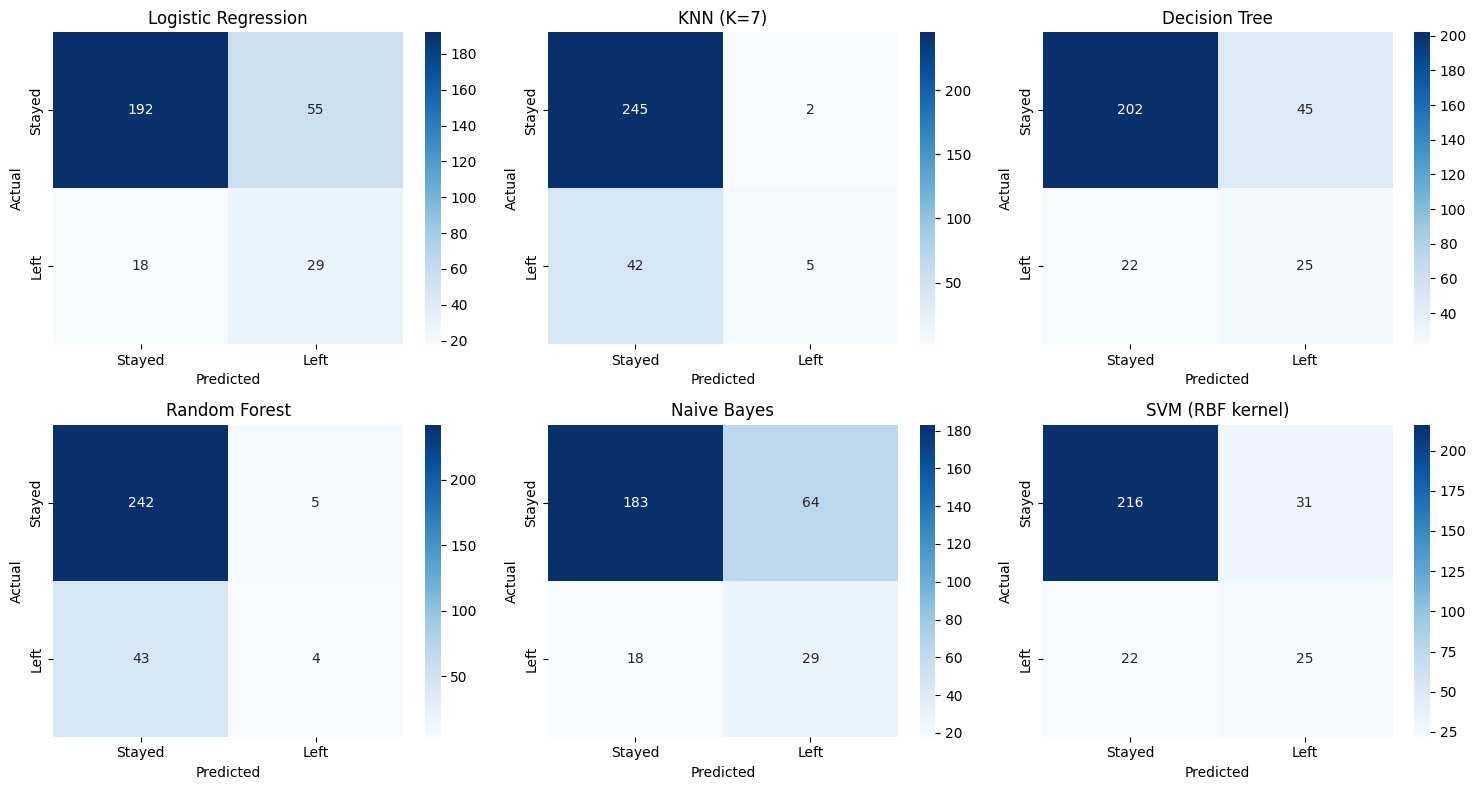

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (name, (model, pred)) in zip(axes.ravel(), fitted.items()):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Stayed", "Left"], yticklabels=["Stayed", "Left"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

## Q22. 5-fold cross-validation
One train/test split has only 47 leavers in the test set, so scores can change a lot with a different split. Cross-validation trains and tests 5 times on different parts of the data and averages the scores.

In [22]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_rows = []

for name, (model, needs_scaling) in all_models.items():
    # for scaled models, a pipeline re-fits the scaler inside each fold (avoids data leakage)
    estimator = make_pipeline(StandardScaler(), model) if needs_scaling else model
    s = cross_validate(estimator, X, y, cv=cv, scoring=["accuracy", "precision", "recall", "f1"])
    cv_rows.append({
        "Model": name,
        "Accuracy": s["test_accuracy"].mean(),
        "Precision": s["test_precision"].mean(),
        "Recall": s["test_recall"].mean(),
        "F1": s["test_f1"].mean(),
        "F1 std": s["test_f1"].std(),
    })

cv_results = pd.DataFrame(cv_rows).sort_values("F1", ascending=False).round(3)
cv_results

,Model,Accuracy,Precision,Recall,F1,F1 std
5,SVM (RBF kernel),0.832,0.484,0.570,0.523,0.024
0,Logistic Regression,0.754,0.366,0.713,0.483,0.019
4,Naive Bayes,0.756,0.360,0.637,0.458,0.027
2,Decision Tree,0.772,0.372,0.574,0.449,0.036
3,Random Forest,0.854,0.878,0.118,0.204,0.060
1,KNN (K=7),0.844,0.608,0.101,0.173,0.041


## Q23. Compare models visually (cross-validated recall and F1)

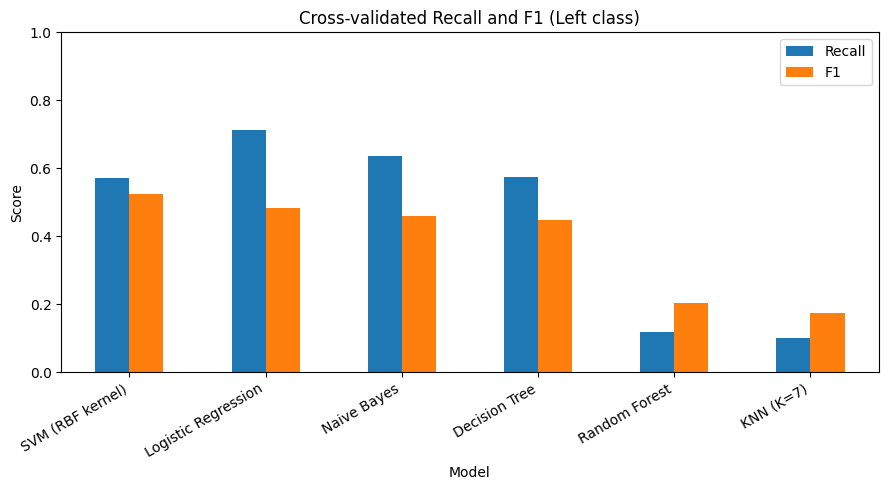

In [23]:
plot_df = cv_results.set_index("Model")[["Recall", "F1"]]
plot_df.plot(kind="bar", figsize=(9, 5))
plt.title("Cross-validated Recall and F1 (Left class)")
plt.ylabel("Score")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

## Q24. Which features matter? (Random Forest importance and Decision Tree)

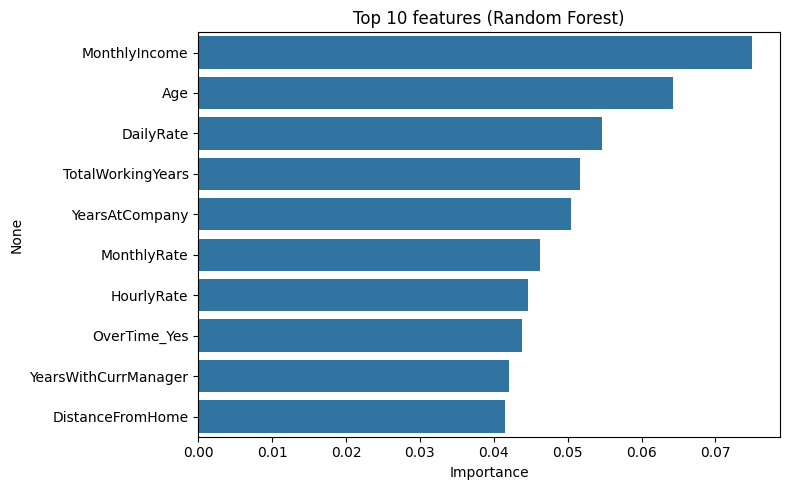

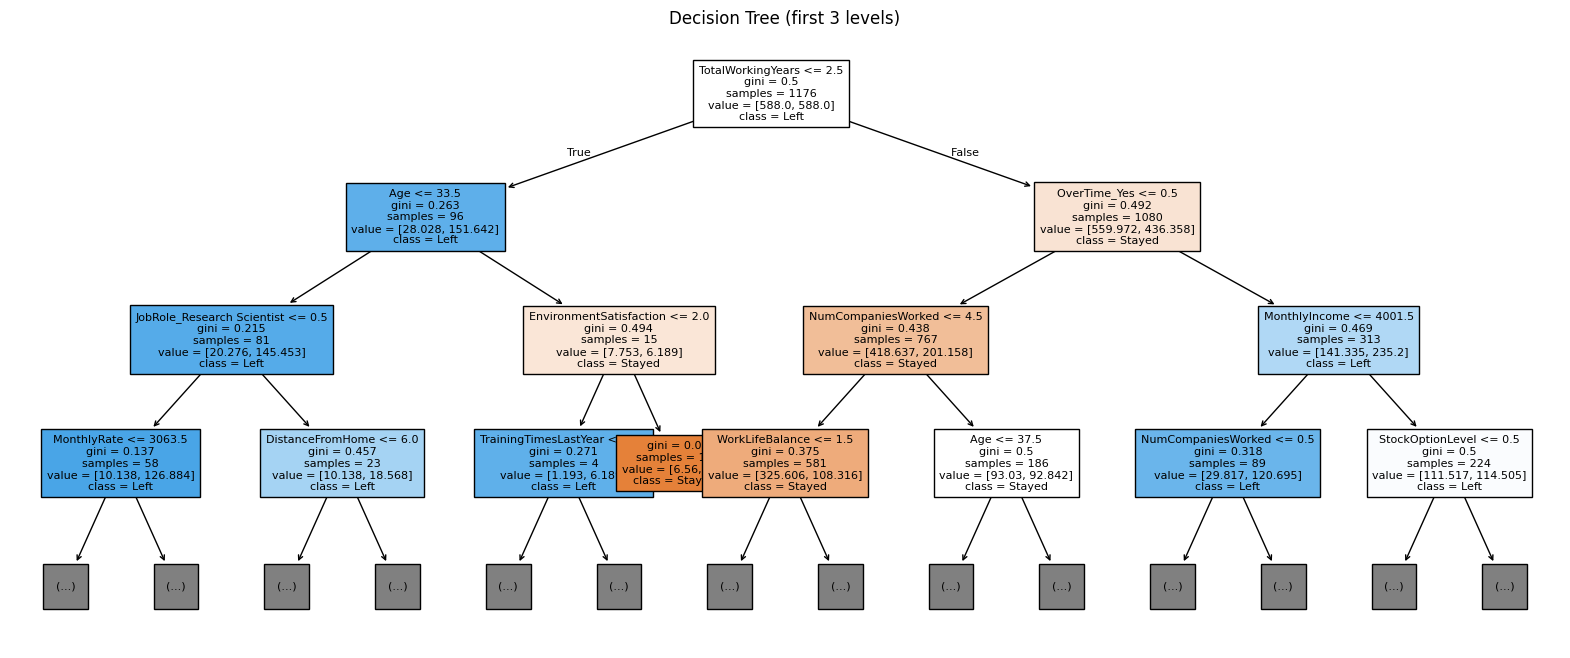

In [24]:
rf_model = fitted["Random Forest"][0]
importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 5))
sns.barplot(x=importances.values, y=importances.index)
plt.title("Top 10 features (Random Forest)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

tree_model = fitted["Decision Tree"][0]
plt.figure(figsize=(20, 8))
plot_tree(tree_model, feature_names=X.columns, class_names=["Stayed", "Left"],
          max_depth=3, filled=True, fontsize=8)
plt.title("Decision Tree (first 3 levels)")
plt.show()

# Section 4: Employee Segmentation (K-Means)

Classification tells us **who** might leave. Clustering finds **which kinds of employees** exist, so we can see which segments have the highest attrition. The attrition column is NOT used to form the clusters. We use it only afterwards to measure each cluster.

## Q25. Choose features and scale them

In [25]:
cluster_cols = ["Age", "MonthlyIncome", "TotalWorkingYears", "YearsAtCompany",
                "YearsSinceLastPromotion", "JobLevel", "JobSatisfaction",
                "WorkLifeBalance", "EnvironmentSatisfaction",
                "DistanceFromHome", "OverTime_Yes"]

# K-Means uses distances, so features must be on the same scale
Xc = StandardScaler().fit_transform(X[cluster_cols].astype(float))
print(Xc.shape)

(1470, 11)


## Q26. Choose K: Elbow method and silhouette score

2 12358.0 0.313
3 11141.9 0.164
4 10394.7 0.125
5 9759.0 0.148
6 9173.7 0.129
7 8747.1 0.126
8 8419.1 0.116


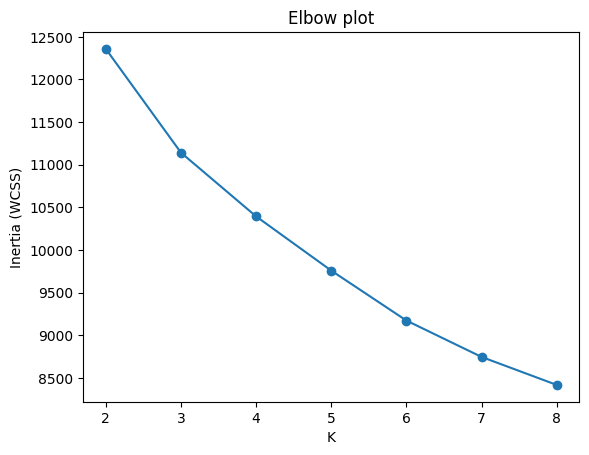

In [26]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertias, sils = [], []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xc)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(Xc, km.labels_))
    print(k, round(km.inertia_, 1), round(sils[-1], 3))

plt.plot(range(2, 9), inertias, marker="o")
plt.xlabel("K")
plt.ylabel("Inertia (WCSS)")
plt.title("Elbow plot")
plt.show()

The elbow curve bends gently, so there is no sharp elbow. K=2 has the best silhouette score but is too coarse to be useful, so we choose K=5 as a balance between segment detail and cluster quality.

## Q27. Fit K-Means (K=5) and calculate the attrition rate of each segment

In [27]:
km = KMeans(n_clusters=5, n_init=10, random_state=42).fit(Xc)

seg = X[cluster_cols].copy()
seg["Cluster"] = km.labels_
seg["AttritionFlag"] = y.values

summary = seg.groupby("Cluster").agg(
    Size=("AttritionFlag", "size"),
    AttritionRate=("AttritionFlag", "mean"),
).round(3)

profile = seg.groupby("Cluster")[cluster_cols].mean().round(2)

print(summary, "\n")
print(profile.T)

         Size  AttritionRate
Cluster                     
0         232          0.147
1         146          0.055
2         122          0.115
3         634          0.104
4         336          0.342 

Cluster                        0         1         2        3        4
Age                        35.00     48.86     44.75    34.48    34.84
MonthlyIncome            4965.44  15080.79  13978.74  4602.42  4708.89
TotalWorkingYears           9.11     23.97     24.12     8.17     8.47
YearsAtCompany              5.79      7.12     21.66     5.47     5.38
YearsSinceLastPromotion     1.56      1.71      8.98     1.53     1.60
JobLevel                    1.75      3.93      3.79     1.63     1.65
JobSatisfaction             2.69      2.73      2.66     2.72     2.80
WorkLifeBalance             2.69      2.75      2.77     2.81     2.73
EnvironmentSatisfaction     2.62      2.81      2.65     2.70     2.83
DistanceFromHome           21.58      8.50      8.99     4.98     8.96
OverTime_Yes  

## Q28. Visualize the segments

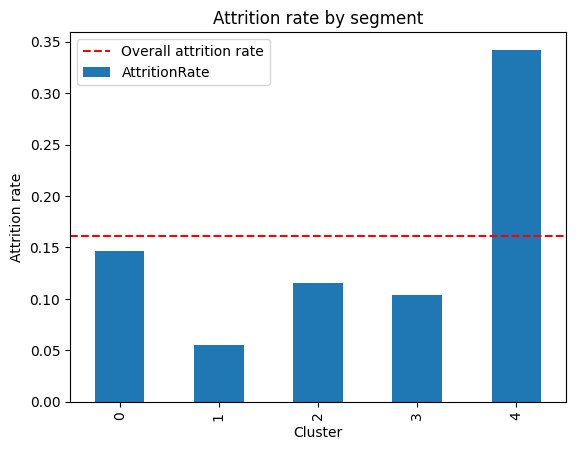

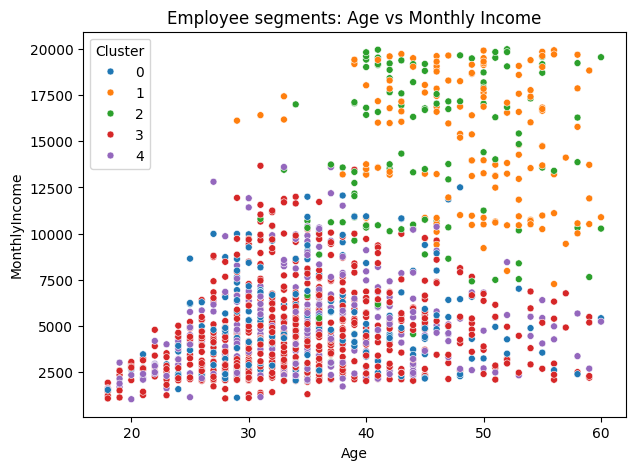

In [28]:
summary["AttritionRate"].plot(kind="bar")
plt.axhline(y.mean(), color="red", linestyle="--", label="Overall attrition rate")
plt.ylabel("Attrition rate")
plt.title("Attrition rate by segment")
plt.legend()
plt.show()

plt.figure(figsize=(7, 5))
sns.scatterplot(x=seg["Age"], y=seg["MonthlyIncome"], hue=seg["Cluster"], palette="tab10", s=25)
plt.title("Employee segments: Age vs Monthly Income")
plt.show()

## Conclusion
- Overtime, job role, marital status and business travel show clear differences in attrition rate (EDA).
- Because only about 16% of employees leave, accuracy is misleading. Models are compared on **recall and F1 for the Left class**, using both a train/test split and 5-fold cross-validation.
- The best model is the one with the strongest cross-validated recall and F1 (see Q22 and Q23).
- K-Means segmentation shows which kinds of employees have the highest attrition (Q27).
- These results show association, not cause.